In [2]:
import pandas as pd
import numpy as np

# 设置显示所有列
pd.set_option('display.max_columns', None)

data = pd.read_csv('loan_net.csv', skipinitialspace=True)
data.head()

,net_size,degree,average_neighbor_degree,percentage,flag
0,2,1,1.0,0.0,1
1,2,1,1.0,0.0,0
2,2,1,1.0,0.0,0
3,2,1,1.0,0.0,0
4,2,1,1.0,0.0,0


In [3]:
from sklearn.model_selection import train_test_split

target = data['flag'].copy()
data = data.iloc[:, :4].copy()

# 划分训练集和测试集
train_data, test_data, train_target, test_target = train_test_split(
    data, target, test_size=0.4, train_size=0.6 ,random_state=1234) 
print('TrainSet size: ', len(train_data))
print('TestSet size: ', len(test_data))

TrainSet size:  16392
TestSet size:  10929


In [4]:
# 网格搜索参数
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

param_grid = {
    'criterion': ['entropy', 'gini'],  # 当前支持计算信息增益和GINI
    'max_depth': [2, 3, 4, 5],         # 树的最大深度
    'min_samples_split': [2, 4, 6, 8, 10],  # 停止分裂的最小样本量
    'min_samples_leaf': [2, 4, 6, 8, 10],   # 停止分裂的叶节点最小样本量
    'class_weight': [{0:1, 1:1}, {0:1, 1:2}, {0:1, 1:3}] # 类别的权重
}
dtree = DecisionTreeClassifier()
dtree_cv = GridSearchCV(estimator=dtree, param_grid=param_grid, 
                   scoring='roc_auc', cv=4)
dtree_cv.fit(train_data, train_target)

print('Best parameters generated by grid search: \n', dtree_cv.best_params_)

Best parameters generated by grid search: 
 {'class_weight': {0: 1, 1: 1}, 'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 2, 'min_samples_split': 2}


### scikit-learn可以将决策树的图形输出出来，但需要安装graphviz和相应的插件：
1. 安装graphviz。如果是linux，可以用apt-get或者yum安装。如果是windows，请在[官网](http://www.graphviz.org/) 下载msi文件安装。无论是linux还是windows，装完后都要将graphviz的bin目录加到环境变量PATH中：以windows 10为例，在系统搜索栏输入“编辑系统环境变量”打开，在“高级->环境变量-> 编辑->新建”中，添加你安装的Graphviz的bin目录（如“C:\Program Files (x86)\Graphviz2.38\bin\”），并重启；
2. 安装python插件graphviz：在cmd中使用pip install graphviz；
3. 安装python插件pydotplus：在cmd中使用pip install pydotplus；


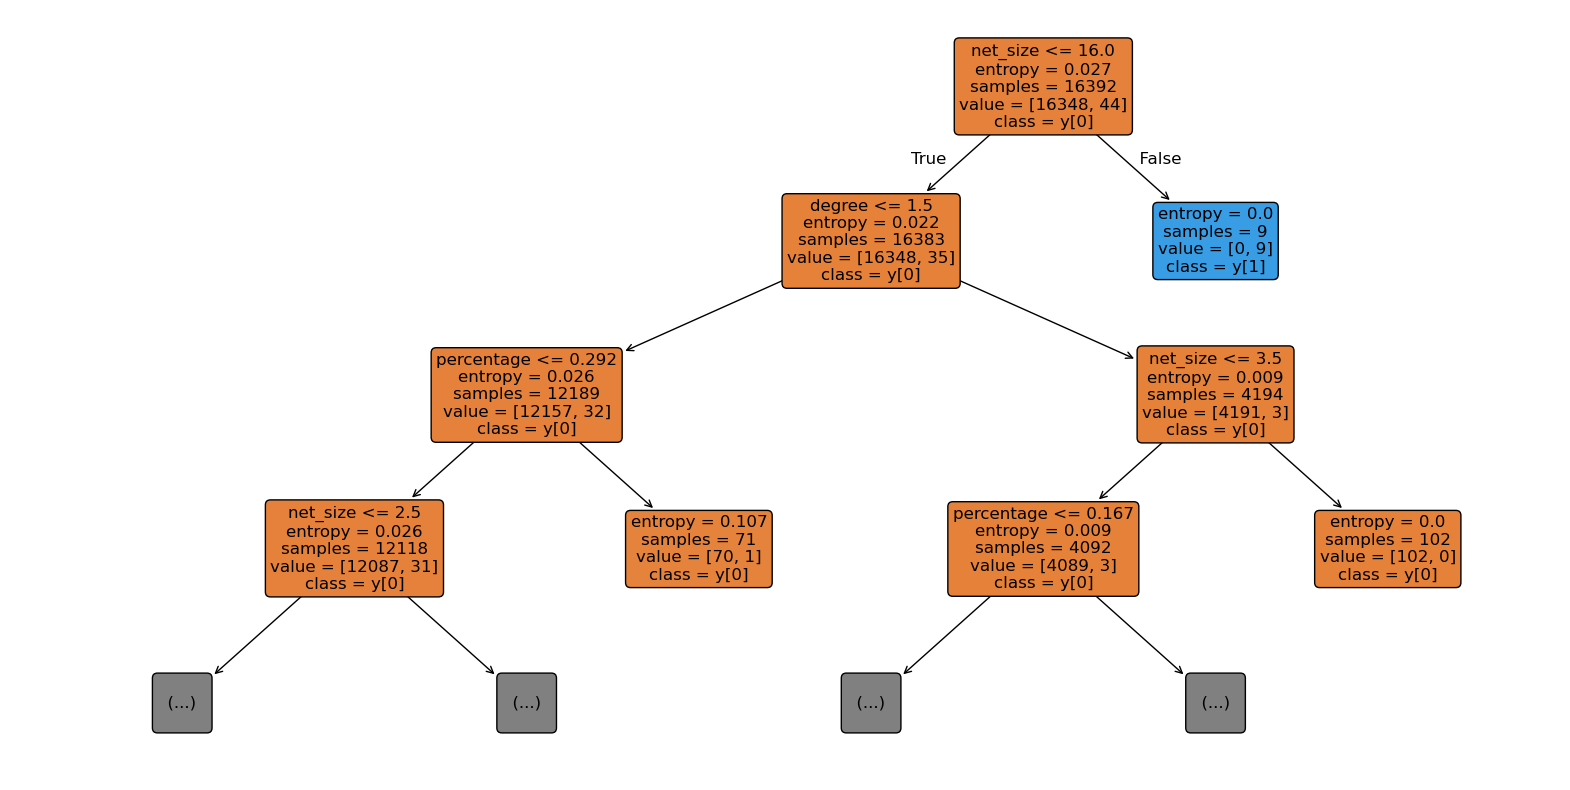

In [6]:
import matplotlib.pyplot as plt
import sklearn.tree as tree

%matplotlib inline

# 获取网格搜索的最优模型
best_tree = dtree_cv.best_estimator_

# 设置画布大小，保证树能显示清楚
plt.figure(figsize=(20, 10))

# 使用 sklearn 自带的 plot_tree 绘图
tree.plot_tree(
    best_tree, 
    feature_names=data.columns,
    max_depth=3,          # 限制显示的最大深度为3
    class_names=True,     # 显示类别名称
    filled=True,          # 节点填充颜色
    rounded=True,         # 节点使用圆角
    fontsize=12           # 字体大小
)

# 显示图像
plt.show()

In [7]:
from sklearn.metrics import classification_report

# 预测值
test_est = best_tree.predict(test_data)
train_est = best_tree.predict(train_data)

#  计算评估指标
print('Classification report on test:')
print(classification_report(test_target, test_est, digits=3))

Classification report on test:
              precision    recall  f1-score   support

           0      0.998     1.000     0.999     10902
           1      1.000     0.259     0.412        27

    accuracy                          0.998     10929
   macro avg      0.999     0.630     0.705     10929
weighted avg      0.998     0.998     0.998     10929



In [8]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score
from sklearn.metrics import roc_curve, auc

# 绘制ROC、PR、KS曲线
def plot_metrics_curve(test_target, train_target, test_proba, train_proba):
    fpr_test, tpr_test, th_test = roc_curve(test_target, test_proba)
    fpr_train, tpr_train, th_train = roc_curve(train_target, train_proba)
    precision_test, recall_test, _ = precision_recall_curve(test_target, 
                                                            test_proba)
    precision_train, recall_train, _ = precision_recall_curve(train_target,
                                                              train_proba)
    
    #  ROC curve
    plt.figure(figsize=[6, 6])
    plt.subplot(221)
    plt.plot(fpr_test, tpr_test, 'b--')
    plt.plot(fpr_train, tpr_train, 'r-')
    plt.xlabel('fpr')
    plt.ylabel('tpr')
    plt.title('ROC curve:Test is dotted line')
    
    # PR curve
    plt.subplot(222)
    plt.plot(recall_test, precision_test, 'b--')
    plt.plot(recall_train, precision_train, 'r-')
    plt.xlabel('recall')
    plt.ylabel('precision')
    plt.title('PR curve:Test is dotted line')
    
    # KS curve, 曲线按阈值降序排列，所以需要1-threshold镜像
    plt.subplot(212)
    plt.plot(1 - th_test, tpr_test, 'b--', label='tpr') 
    plt.plot(1 - th_test, fpr_test, 'b:', label='fpr')
    plt.plot(1 - th_test, tpr_test - fpr_test, 'r-', label='tpr-fpr')
    plt.xlabel('score')
    plt.title('KS Curve  KS= %0.2f' %max(tpr_test - fpr_test))
    legend = plt.legend(loc='upper left', shadow=True, fontsize='x-large')
    
    plt.tight_layout()
    plt.show()
    
    # Print ROC-AUC 
    print('TestAUC=%.4f,' %auc(fpr_test, tpr_test),
          'TrainAUC=%.4f' %auc(fpr_train, tpr_train))
    # Print average precision score
    print('TestAP=%.4f,'%average_precision_score(test_target,test_proba),
          'TrainAP=%.4f'%average_precision_score(train_target,train_proba))

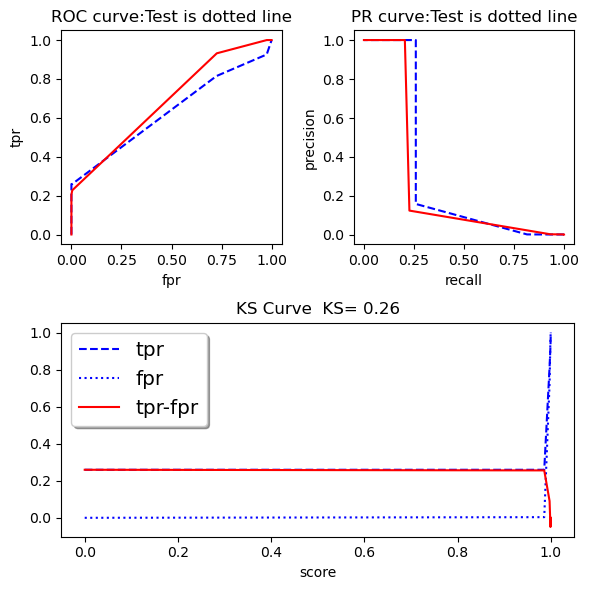

TestAUC=0.6302, TrainAUC=0.6846
TestAP=0.2612, TrainAP=0.2100


In [9]:
# 预测概率
test_proba = best_tree.predict_proba(test_data)[:, 1]  
train_proba = best_tree.predict_proba(train_data)[:, 1]

# 绘制评估图形
plot_metrics_curve(test_target, train_target, test_proba, train_proba)     

保存模型

In [10]:
import os
import joblib

output_dir = "./model"
if not os.path.exists(output_dir):
    os.mkdir(output_dir)
    
save_path = os.path.join(output_dir, "fraud_detection_dtree.model")

# 模型持久化
joblib.dump(best_tree, save_path)
# 读取模型
best_tree_load = joblib.load(save_path)

In [11]:
def tree(net_size, degree, average_neighbor_degree, percentage):
    if net_size <= 16.0:
        if degree <= 1.5:
            if percentage <= 0.2916666716337204:
                if net_size <= 2.5:
                    return [[11802., 31.]]
                else:  # if net_size > 2.5
                    return [[285., 0.]]
            else:  # if percentage > 0.2916666716337204
                return [[70., 1.]]
        else:  # if degree > 1.5
            if average_neighbor_degree <= 1.1666666865348816:
                if net_size <= 3.5:
                    if percentage <= 0.1666666716337204:
                        return [[4082., 3.]]
                    else:  # if percentage > 0.1666666716337204
                        return [[3., 0.]]
                else:  # if net_size > 3.5
                    return [[4., 0.]]
            else:  # if average_neighbor_degree > 1.1666666865348816
                return [[102., 0.]]
    else:  # if net_size > 16.0
        return [[0., 9.]]
    
tree(2,1,1.0,0.0)

[[11802.0, 31.0]]

In [12]:
data.head()

,net_size,degree,average_neighbor_degree,percentage
0,2,1,1.0,0.0
1,2,1,1.0,0.0
2,2,1,1.0,0.0
3,2,1,1.0,0.0
4,2,1,1.0,0.0


In [13]:
# 可以将决策树生成`if - then-`规则
from sklearn.tree import _tree

def tree_to_code(tree, feature_names):
    tree_ = tree.tree_
    feature_name = [
        feature_names[i] 
        if i != _tree.TREE_UNDEFINED else "undefined!"
        for i in tree_.feature
    ]
    print("def tree({}):".format(", ".join(feature_names)))

    def recurse(node, depth):
        indent = "  " * depth
        if tree_.feature[node] != _tree.TREE_UNDEFINED:
            name = feature_name[node]
            threshold = tree_.threshold[node]
            print("{}if {} <= {}:".format(indent, name, threshold))
            recurse(tree_.children_left[node], depth + 1)
            print("{}else:  # if {} > {}".format(
                    indent, name, threshold))
            recurse(tree_.children_right[node], depth + 1)
        else:
            print("{}return {}".format(indent, tree_.value[node]))

    recurse(0, 1)

In [14]:
tree_to_code(best_tree, data.columns)

def tree(net_size, degree, average_neighbor_degree, percentage):
  if net_size <= 16.0:
    if degree <= 1.5:
      if percentage <= 0.2916666716337204:
        if net_size <= 2.5:
          return [[0.99738021 0.00261979]]
        else:  # if net_size > 2.5
          return [[1. 0.]]
      else:  # if percentage > 0.2916666716337204
        return [[0.98591549 0.01408451]]
    else:  # if degree > 1.5
      if net_size <= 3.5:
        if percentage <= 0.1666666716337204:
          if average_neighbor_degree <= 1.5:
            return [[9.99265606e-01 7.34394125e-04]]
          else:  # if average_neighbor_degree > 1.5
            return [[1. 0.]]
        else:  # if percentage > 0.1666666716337204
          return [[1. 0.]]
      else:  # if net_size > 3.5
        return [[1. 0.]]
  else:  # if net_size > 16.0
    return [[0. 1.]]


### Random forests

In [15]:
import sklearn.ensemble as ensemble
from sklearn.model_selection import GridSearchCV

param_grid = {
    'criterion':['gini'], # 子树分裂使用的指标
    'max_depth':[8],      # 子树的最大深度
    'n_estimators':[13],  # 子树的个数
    'max_features':[0.5, 0.6, 0.7], # 每棵子树使用的变量占比
    'min_samples_split':[2, 3, 4]   # 子树停止分裂的最小样本量
}

rfc = ensemble.RandomForestClassifier()
# 交叉验证
rfc_cv = GridSearchCV(estimator=rfc, param_grid=param_grid, scoring='f1', cv=4)
rfc_cv.fit(train_data, train_target)
print('Best parameters : \n', rfc_cv.best_params_)

Best parameters : 
 {'criterion': 'gini', 'max_depth': 8, 'max_features': 0.5, 'min_samples_split': 2, 'n_estimators': 13}


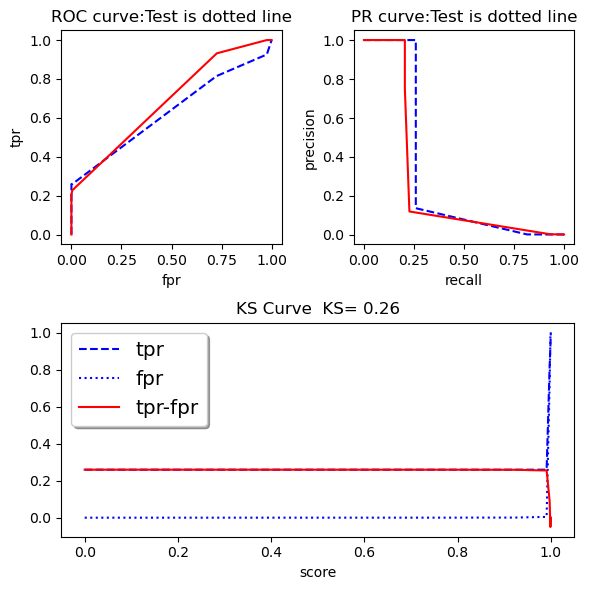

TestAUC=0.6298, TrainAUC=0.6844
TestAP=0.2612, TrainAP=0.2099


In [16]:
best_rf = rfc_cv.best_estimator_  # 网格搜索得到的最优模型

# 预测值
train_est = best_rf.predict(train_data)
test_est = best_rf.predict(test_data)
# 预测概率
train_proba = best_rf.predict_proba(train_data)[:, 1]
test_proba = best_rf.predict_proba(test_data)[:, 1]
# 绘制评估图形
plot_metrics_curve(test_target, train_target, test_proba, train_proba)

### Adaboost


In [17]:
from sklearn.ensemble import AdaBoostClassifier

param_grid = {
    'n_estimators':[15, 20, 25],     # 子模型个数
    'learning_rate':[0.5, 1.0, 1.5], # 学习率
}

adaboost = AdaBoostClassifier()
# 交叉验证
adaboost_cv = GridSearchCV(estimator=adaboost, param_grid=param_grid, scoring='recall', cv=4)
adaboost_cv.fit(train_data, train_target)

best_ada = adaboost_cv.best_estimator_  # 网格搜索得到的最优模型

# 预测值
test_est = best_ada.predict(test_data)
# 预测概率
test_proba = best_ada.predict_proba(test_data)[:, 1]

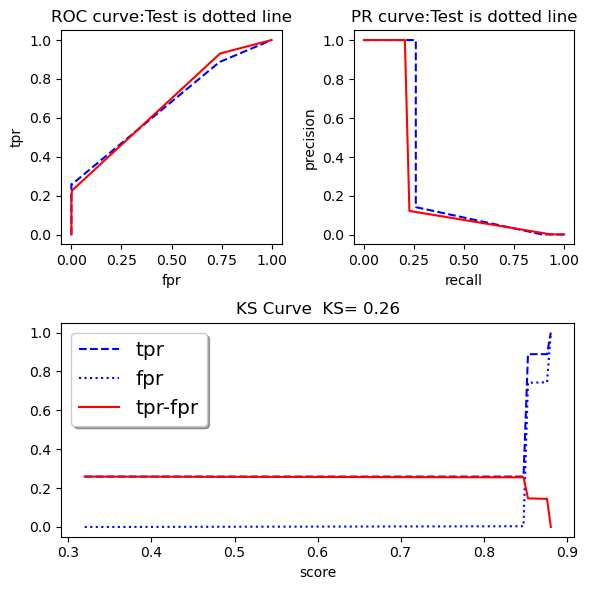

TestAUC=0.6684, TrainAUC=0.6769
TestAP=0.2614, TrainAP=0.2099


In [18]:
# 预测值
train_est = best_ada.predict(train_data)
test_est = best_ada.predict(test_data)
# 预测概率
train_proba = best_ada.predict_proba(train_data)[:, 1]
test_proba = best_ada.predict_proba(test_data)[:, 1]
# 绘制评估图形
plot_metrics_curve(test_target, train_target, test_proba, train_proba)

### xgboost

In [19]:
from xgboost.sklearn import XGBClassifier
from sklearn.model_selection import GridSearchCV
import pprint

xgb = XGBClassifier(
        max_depth=3, 
        learning_rate=0.1, 
        n_estimators=100, 
        eval_metric='auc',
        early_stopping_rounds=3
)

xgb.fit(train_data, train_target, 
        eval_set=[[test_data, test_target],], 
        verbose=False
)

pprint.pprint(xgb.evals_result())
print('best_score:', xgb.best_score)
print('best_iteration:', xgb.best_iteration)

{'validation_0': OrderedDict([('auc',
                               [0.6296296296296297,
                                0.6296296296296297,
                                0.6296296296296297,
                                0.6296296296296297])])}
best_score: 0.6296296296296297
best_iteration: 0


## 以下寻优代码需要把sklearn版本降低至1.6以下
xgboost不能与sklearn配合的问题：
先查看当前sklearn版本
import sklearn
print(sklearn._version_)
conda install scikit-learn=1.6.1

之后把Scikit-learn版本降低到1.5.2

pip uninstall scikit-learn
pip install scikit-learn==1.5.2

conda remove scikit-learn
conda install scikit-learn=1.5.2

如果有问题，再回到1.6.1
pip uninstall scikit-learn
pip install scikit-learn==1.6.12

In [20]:
from xgboost.sklearn import XGBClassifier
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [50, 100, 150],
    'reg_lambda': np.arange(0.01, 1, 0.2) ,
    'max_depth': [2, 3, 5],
    'learning_rate' :[0.5, 1]
}

xgb = XGBClassifier(
    objective='binary:logistic',  # 选择目标函数类型
    verbosity=0,                  # 控制日志输出级别
    use_label_encoder=False,     # 选择不使用标签编码，消除警告
    random_state=1234,
)

xgb_cv = GridSearchCV(
    estimator=xgb,                # 待调参的模型
    param_grid=param_grid,        # 参数搜索空间
    cv=4,                         # 交叉验证折数
    scoring='recall',             # 评估交叉验证指标
    n_jobs=-1                     # 并行程度
)

xgb_cv.fit(train_data, train_target)  

print('best_params:', xgb_cv.best_params_)
print('best_score:', xgb_cv.best_score_)

best_params: {'learning_rate': 0.5, 'max_depth': 2, 'n_estimators': 50, 'reg_lambda': 0.01}
best_score: 0.20454545454545453


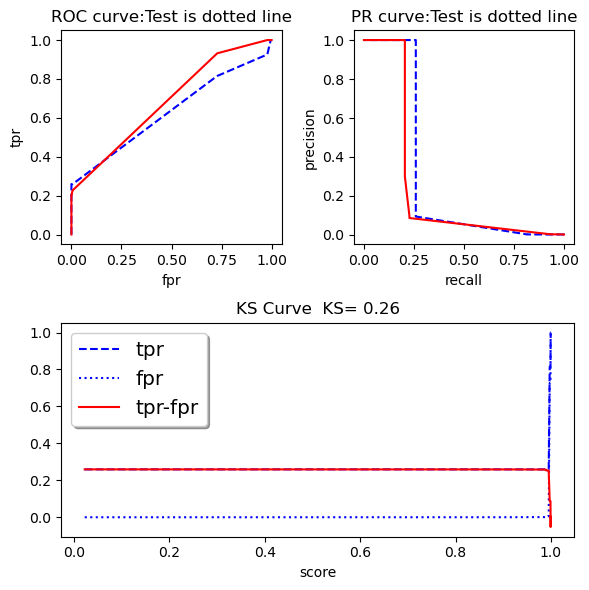

TestAUC=0.6284, TrainAUC=0.6829
TestAP=0.2612, TrainAP=0.2094


In [21]:
# 选取最优模型
best_xgb = xgb_cv.best_estimator_
# 预测值
train_est = best_xgb.predict(train_data)
test_est = best_xgb.predict(test_data)
# 预测概率
train_proba = best_xgb.predict_proba(train_data)[:, 1]
test_proba = best_xgb.predict_proba(test_data)[:, 1]
# 绘制评估图形
plot_metrics_curve(test_target, train_target, test_proba, train_proba)

from xgboost import plot_tree

fig = plt.figure(figsize=[8, 8])
ax = plt.subplot()
plot_tree(best_xgb, num_trees=0, ax=ax)
plt.show(ax)

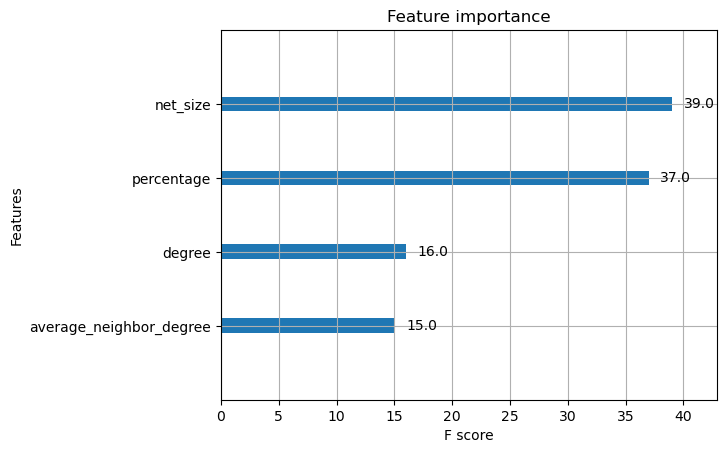

In [22]:
from xgboost import plot_importance

plot_importance(best_xgb)
plt.show()

### lightgbm 
 `pip install lightgbm` first!

In [21]:
#  lightgbm原生API
# import lightgbm as lgb

# lgb_train = lgb.Dataset(train_data, train_target)
# lgb_eval = lgb.Dataset(test_data, test_target, reference=lgb_train)

# # 以字典表示超参数
# params = {
#     'task': 'train',
#     'boosting_type': 'gbdt',  # 提升类型
#     'objective': 'binary',  # 目标函数
#     'metric': {'auc','binary_logloss'}, # 评估指标
#     'min_data_in_leaf': 3,  #  叶节点最小样本量
#     'num_leaves': 28,      #  叶节点数量
#     'max_depth':3,
#     'learning_rate': 0.05,
#     'feature_fraction': 0.8,  #  变量的抽样比例
#     'bagging_fraction': 0.6,  #  样本的抽样比例
# #     'bagging_freq': 5,        #  
#     'is_unbalance': True,   #  样本是否平衡
#     'verbose': 0
# }

# print('Start training...')
# # train
# gbm = lgb.train(params,
#                 lgb_train,
#                 num_boost_round=20,
#                 valid_sets=lgb_eval,
#                 early_stopping_rounds=5)

# print('Save model...')
# # save model to file
# gbm.save_model('model.txt')

参数调优--随机参数搜索

In [25]:
import lightgbm as lgb
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform

param_distributions = {
    'num_leaves': randint(5, 50),   # 叶节点数
    'max_depth':  randint(2, 5),    # 子树最大深度
    'learning_rate': [0.04, 0.08],  # 学习率
    'n_estimators':randint(30,100), # 子树数量
    'min_child_samples':[10, 20],   # 叶节点的最少样本量
    'subsample':[0.5],              # 样本采样比例
    'colsample_bytree':[0.5],       # 特征采样比例
    'reg_alpha': uniform(1, 5),     # 正则化系数
    'reg_lambda':uniform(1, 5),     # 正则化系数
    'cat_smooth':uniform(3, 10)     # 对categorical类型特征的平滑
}
n_iter = 300    # 执行300次随机参数搜索
gbm = lgb.LGBMClassifier()
gbm_cv = RandomizedSearchCV(
    gbm,
    param_distributions=param_distributions, 
    scoring='recall', 
    n_iter=n_iter,
    cv=4,
    random_state=12345,
    verbose=0,
    n_jobs=-1
)

gbm_cv.fit(train_data, train_target)
print('best_params:', gbm_cv.best_params_)
print('best_score:', gbm_cv.best_score_)

[LightGBM] [Info] Number of positive: 44, number of negative: 16348
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000474 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 29
[LightGBM] [Info] Number of data points in the train set: 16392, number of used features: 4
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.002684 -> initscore=-5.917671
[LightGBM] [Info] Start training from score -5.917671
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -in

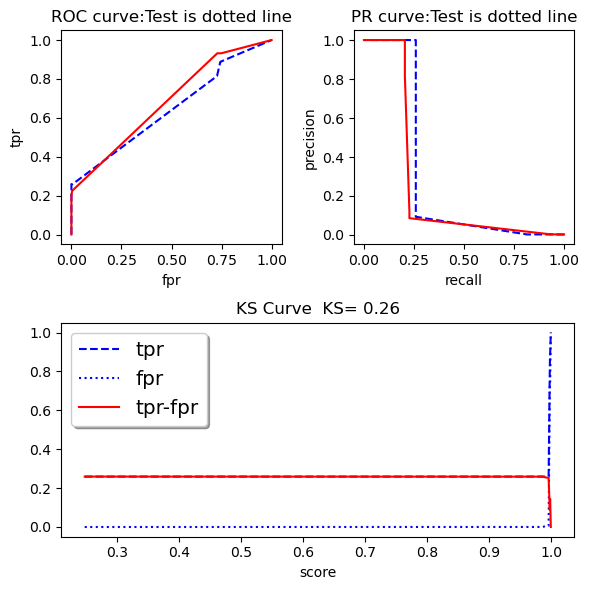

TestAUC=0.6448, TrainAUC=0.6815
TestAP=0.2613, TrainAP=0.2099


In [26]:
# 选择最优模型
best_gbm = gbm_cv.best_estimator_

# predict and plot metrics
train_proba = best_gbm.predict_proba(train_data)[:, 1]
test_proba = best_gbm.predict_proba(test_data)[:, 1]
plot_metrics_curve(test_target, train_target, test_proba, train_proba)  

In [27]:
import os
import joblib

output_dir = "./model"
if not os.path.exists(output_dir):
    os.mkdir(output_dir)
    
save_path = os.path.join(output_dir, "fraud_detection_lightGBM.model")

# 模型持久化
joblib.dump(best_gbm, save_path)
# 读取模型
gbm_load = joblib.load(save_path)
